## Qualitative Analysis

1. Label validity: Does the original gold label (RQ/IQ) still hold with the swapped context?
2. Coherence: Does the swapped context form a make sense with the target question?
3. Prediction sensitivity: Do Logistic Regression and RoBERTa change their predictions? Does that correspond to a plausible change in interpretation?

In [18]:
# imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.metrics import roc_auc_score

In [2]:
# loading processed data and saved predictions

test = pd.read_json("../data/test_processed.jsonl", lines=True)

lr = pd.read_csv("lr_predictions.csv")
roberta = pd.read_csv("roberta_predictions.csv")

In [3]:
# combining both model predictions into one dataframe

df = lr.merge(
    roberta,
    on="id",
    suffixes=("_lr", "_roberta"),
    validate="one_to_one"
)

# sanity checking size, question-matching, and order
assert len(df) == len(test) == 438
assert (df["question_lr"] == df["question_roberta"]).all()
assert (df["question_lr"].to_numpy() == test["question"].to_numpy()).all()

# adding the contexts
df["original_context"] = test["preceding_turns"].to_numpy()
df["swapped_context"] = test["swapped_context"].to_numpy()

# identifying changed predictions for both models
df["lr_changed"] = df["lr_real"] != df["lr_swapped"]
df["roberta_changed"] = df["roberta_real"] != df["roberta_swapped"]

In [4]:
# choosing samples from specific categories of prediction changes between real and swapped context

label_map = {0: "informational", 1: "rhetorical"}

df["roberta_real_label"] = df["roberta_real"].map(label_map)
df["roberta_swapped_label"] = df["roberta_swapped"].map(label_map)

# defining the five groups
both = df["lr_changed"] & df["roberta_changed"]
same_direction = df["lr_real"] == df["roberta_real_label"]

groups = {
    "both_same": df[both & same_direction],
    "both_opposite": df[both & ~same_direction],
    "lr_only": df[df["lr_changed"] & ~df["roberta_changed"]],
    "roberta_only": df[~df["lr_changed"] & df["roberta_changed"]],
    "neither": df[~df["lr_changed"] & ~df["roberta_changed"]]
}

# getting samples with random seed 42 (2 for each group)
samples = []

for name, group in groups.items():
    selected = group.sample(n=4, random_state=42).copy() # changed from 2 to 4
    selected["category"] = name
    samples.append(selected)

qualitative_sample = pd.concat(samples, ignore_index=True)

In [5]:
# exporting annotation sheet for manual analysis

columns = [
    "id", "category", "question_lr", "gold_lr",
    "original_context", "swapped_context",
    "lr_real", "lr_swapped",
    "roberta_real_label", "roberta_swapped_label"
]

qualitative_sample[columns].to_csv(
    "qualitative_analysis.csv",
    index=False
)

Results: 
 
...

### Are RQs or IQs more affected by context swapping?

In [6]:
# calculating prediction-change rates by original gold label

results = df.groupby("gold_lr").agg(
    n=("id", "count"),
    lr_changes=("lr_changed", "sum"),
    lr_change_rate=("lr_changed", "mean"),
    roberta_changes=("roberta_changed", "sum"),
    roberta_change_rate=("roberta_changed", "mean")
)

results["lr_change_rate"] *= 100
results["roberta_change_rate"] *= 100

print(results.round(1))


                 n  lr_changes  lr_change_rate  roberta_changes  \
gold_lr                                                           
informational  140          52            37.1               44   
rhetorical     298          86            28.9              103   

               roberta_change_rate  
gold_lr                             
informational                 31.4  
rhetorical                    34.6  


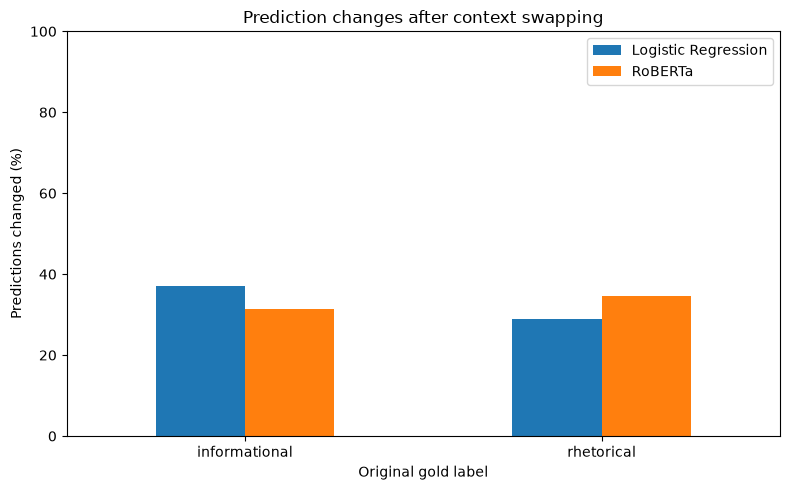

In [7]:
# visualizing results

results[["lr_change_rate", "roberta_change_rate"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Prediction changes after context swapping")
plt.xlabel("Original gold label")
plt.ylabel("Predictions changed (%)")
plt.xticks(rotation=0)
plt.legend(["Logistic Regression", "RoBERTa"])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


Grouped by original gold labels:

- RoBERTa: 31.4% of IQ predictions change to RQ, 34.6% of RQ predictions change to IQ
- Logistic Regression: 37.1% of IQ predictions change to RQ, 28.9% of RQ predictions change to IQ

In [8]:
# calculating prediction-change rates by original predicted class

for model in ["lr", "roberta"]:
    results_pred = df.groupby(f"{model}_real").agg(
        n=("id", "count"),
        changes=(f"{model}_changed", "sum"),
        change_rate=(f"{model}_changed", "mean")
    )

    results_pred["change_rate"] *= 100

    print(f"\n{model.upper()} — by original predicted class")
    print(results_pred.round(1))



LR — by original predicted class
                 n  changes  change_rate
lr_real                                 
informational  134       66         49.3
rhetorical     304       72         23.7

ROBERTA — by original predicted class
                n  changes  change_rate
roberta_real                           
0             118       72         61.0
1             320       75         23.4


Grouped by original predictions:

- RoBERTa: 61.0% of IQ predictions change to RQ, 23.4% of RQ predictions change to IQ
- Logistic Regression: 49.3% of IQ predictions change to RQ, 23.7% of RQ predictions change to IQ


Results:  

- different context sensitivity depending on whether goruped by original gold labels or model predictions
- relatively small differences between gold-label groups + inconsistent across the two models
- less stable IQ predictions for both models (substantially)

### Why does RoBERTa predict almost only IQs in the no context condition?

#### Class bias: does RoBERTa default to predicting IQs without context?

In [9]:
# loading updated RoBERTa predictions CSV
roberta_all = pd.read_csv("roberta_predictions_all.csv")

# adding no-context predictions to the existing merged dataframe
df = df.drop(columns=["roberta_empty"], errors="ignore")

df = df.merge(
    roberta_all[["id", "roberta_empty"]],
    on="id",
    validate="one_to_one"
)

assert len(df) == 438

In [10]:
# RoBERTa prediction counts across conditions

columns = ["roberta_real", "roberta_swapped", "roberta_empty"]

counts = df[columns].apply(
    lambda col: col.value_counts()
).reindex([0, 1], fill_value=0)

counts.index = ["Informational", "Rhetorical"]

print("Prediction counts:")
display(counts)

print("Prediction percentages:")
display((counts / len(df) * 100).round(1))

Prediction counts:


,roberta_real,roberta_swapped,roberta_empty
Informational,118,121,434
Rhetorical,320,317,4


Prediction percentages:


,roberta_real,roberta_swapped,roberta_empty
Informational,26.9,27.6,99.1
Rhetorical,73.1,72.4,0.9


In [11]:
# Prediction transitions: real context -> no context

transition = pd.crosstab(
    df["roberta_real"].map({0: "IQ", 1: "RQ"}),
    df["roberta_empty"].map({0: "IQ", 1: "RQ"}),
    rownames=["Real context"],
    colnames=["No context"]
).reindex(
    index=["IQ", "RQ"],
    columns=["IQ", "RQ"],
    fill_value=0
)

display(transition)

print(
    "Prediction-change rate:",
    f"{(df['roberta_real'] != df['roberta_empty']).mean():.1%}"
)

No context,IQ,RQ
Real context,,
IQ,117,1
RQ,317,3


Prediction-change rate: 72.6%


High prediction change rate (72.6%) between real and empty context.  
- only 33.6% when context is swapped
99.1% or RoBERTa's predictions without context are IQs.  
- prediction changes dominantly in one direction (RQ -> IQ)
- almost balanced with swapped context

- RoBERTa more sensitive to context removal than context replacement
- remove context -> systematic class preferene for IQ (434/438)
- swapping vs. removing context have different effects on predictions

Why?  

- model might associate features of preceding context with RQs
- fine-tuned with context, unused to no context
- input format: empty first sequence in empty context condition

- IQs more likely to not have preceding context (see paper)
    - does RoBERTa know from it's original training data?

In [12]:
# inspecting questions predicted as rhetorical without context

display(
    df.loc[
        df["roberta_empty"] == 1,
        ["id", "question_lr", "gold_lr",
         "roberta_real", "roberta_swapped", "roberta_empty"]
    ]
)

,id,question_lr,gold_lr,roberta_real,roberta_swapped,roberta_empty
1,1,Doctors also look up things (in front of their...,rhetorical,1,0,1
78,78,As for Europe doing fine for hundreds of years...,rhetorical,0,0,1
136,136,What bubble do you live in where you don't get...,rhetorical,1,1,1
363,363,So you would rather us be have a bad economy a...,rhetorical,1,1,1


... !!!

see roberta.ipynb  

Effect of tokenization strategy for empty context:  
Empty context:  
print(tokenizer.decode(tokenizer("", question)["input_ids"]))  
<s></s></s>how so?</s>  
 
Question only:  
print(tokenizer.decode(tokenizer(question)["input_ids"]))  
<s>how so?</s>  

Empty context predictions when tokenizing with just question:  
IQ:    422 (96.3%)  
RQ:     16 (3.7%)  

Empty context predictions when tokenizing with empty string + question:  
IQ:    434 (99.1%)  
RQ:     4 (0.9%)  

(with real context: 73.1% RQs)  

=> only slight effect on the predictions: not responsible for most of the IQ predictions  

=> but we don't know if the predicted RQs are the same examples in both versions

=> might simply respond to distribution shift (??)

see roberta.ipynb  

Question only	IQ	RQ  
Empty paired input  		
IQ	422	12  
RQ	0	4  
Changed predictions: 12  

=> 12 changed from IQ to RQ (when using question-only)  
=> only a small amount of questions affected  
=> real to empty context leads to much bigger shift  

#### Confidence: are IQ predictions confident?
(softmax probabilities)

Input distribution shift: due to fine-tuning with context?

In [13]:
# loading RoBERTa probabilities

probs = pd.read_csv("roberta_probabilities.csv")

df = df.merge(
    probs,
    on="id",
    validate="one_to_one"
)

assert len(df) == 438

In [14]:
# summary statistics across conditions

columns = [
    "iq_prob_real",
    "iq_prob_swapped",
    "iq_prob_empty"
]

display(df[columns].describe().round(3))

# confidence of no-context IQ predictions

no_context_iq = df[df["roberta_empty"] == 0]

print("Number predicted IQ:", len(no_context_iq))

print("Mean IQ probability:",
      round(no_context_iq["iq_prob_empty"].mean(), 3))

print("Median IQ probability:",
      round(no_context_iq["iq_prob_empty"].median(), 3))

print("Proportion above 0.9:",
      round((no_context_iq["iq_prob_empty"] > 0.9).mean(), 3))

print("Proportion above 0.99:",
      round((no_context_iq["iq_prob_empty"] > 0.99).mean(), 3))

,iq_prob_real,iq_prob_swapped,iq_prob_empty
count,438.000,438.000,438.000
mean,0.412,0.413,0.640
std,0.192,0.192,0.036
min,0.129,0.129,0.382
25%,0.264,0.262,0.629
50%,0.354,0.355,0.646
75%,0.515,0.518,0.648
max,0.903,0.905,0.801


Number predicted IQ: 434
Mean IQ probability: 0.641
Median IQ probability: 0.646
Proportion above 0.9: 0.0
Proportion above 0.99: 0.0


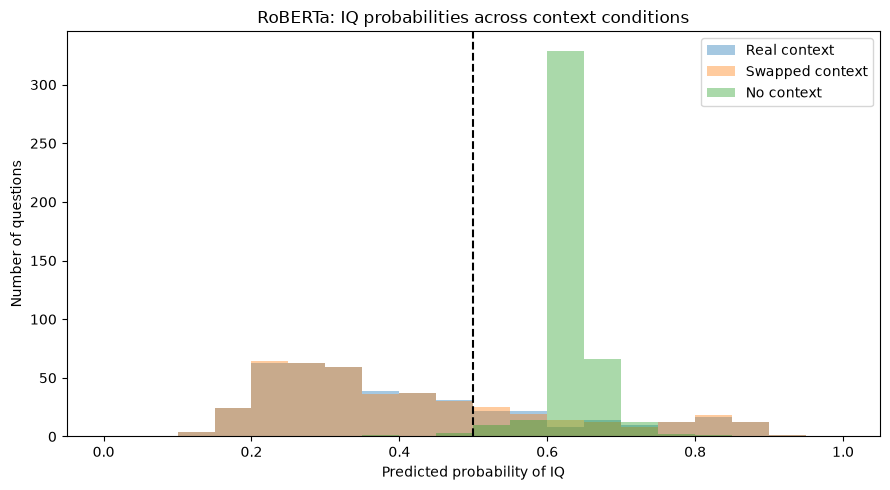

In [15]:
# visualizing distributions

plt.figure(figsize=(9, 5))

for col, label in [
    ("iq_prob_real", "Real context"),
    ("iq_prob_swapped", "Swapped context"),
    ("iq_prob_empty", "No context")
]:
    plt.hist(
        df[col],
        bins=np.linspace(0, 1, 21),
        alpha=0.4,
        label=label
    )

plt.axvline(0.5, color="black", linestyle="--")
plt.xlabel("Predicted probability of IQ")
plt.ylabel("Number of questions")
plt.title("RoBERTa: IQ probabilities across context conditions")
plt.legend()
plt.tight_layout()
plt.show()

- moderate confidence when predicting IQs without context (but higher than for real and swapped context ~23%)
- predicts IQ when IQ probability over 0.5 ???
- lower standard deviation for empty context probabilities (similar outputs regardless of actual labels, for most questions)

- Why? (possibly)
    - contextual features from fine-during absent -> learned baseline preference for IQ
    - maybe also be caused by distribution shift without context

- model does not completely ignore question though -> 4 examples as RQ

In [ ]:
# do empty context IQ probabilities differ with original gold label?

probs = pd.read_csv("roberta_probabilities.csv")
test = pd.read_json("../data/test_processed.jsonl", lines=True)

probs["gold"] = test["label"].to_numpy()

print("IQ probabilities by original gold label:")
display(
    probs.groupby("gold")["iq_prob_empty"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

IQ probabilities by original gold label:


,count,mean,median,std,min,max
gold,,,,,,
informational,140,0.648,0.646,0.032,0.515,0.733
rhetorical,298,0.636,0.640,0.037,0.382,0.801


Very similar between RQ and IQ
- slightly higher probability for IQs
- but overall, little ability to distinguish RQs from IQs

In [ ]:
# calculating ROC AUC (ranking examples independently of classification threshold)

# 1 = informational, 0 = rhetorical
y_true = (probs["gold"] == "informational").astype(int)

auc = roc_auc_score(y_true, probs["iq_prob_empty"])

print(f"No-context ROC AUC: {auc:.3f}")

No-context ROC AUC: 0.652


some ability to distinguish RQs and IQs

assigns higher IQ score to random example 62.5% of the time

- With real context, RoBERTa predicts RQ for 73.1% of examples.  

- With swapped context, the predicted class distribution remains nearly unchanged, despite many individual prediction changes.  

- Without context, 99.1% of examples are predicted as IQ.  

- Systematic preference for IQs

- The no-context IQ probabilities are tightly concentrated around 0.64.  

- These probabilities are very similar for originally rhetorical and informational questions.  

- The IQ preference persists even when using a question-only input format.  

- But some class discrimination info still there (ROC AUC of 62.5%)


This suggests that RoBERTa's predictions depend strongly on the presence of conversational context, but we cannot yet determine whether this reflects meaningful pragmatic interpretation or reliance on contextual features learned during fine-tuning.

### Are short or particular question forms more sensitive?

Question length:  
- 1-3 words: very short
- 4-7 words: short
- 8+ words: longer  
 

In [19]:
# investigating question length and prediction changes

df["question_length"] = df["question_lr"].str.split().str.len()

df["length_group"] = pd.cut(
    df["question_length"],
    bins=[0, 3, 7, float("inf")],
    labels=["1–3 words", "4–7 words", "8+ words"]
)

length_results = df.groupby(
    "length_group", observed=True
).agg(
    n=("id", "count"),
    lr_changes=("lr_changed", "sum"),
    lr_rate=("lr_changed", "mean"),
    roberta_changes=("roberta_changed", "sum"),
    roberta_rate=("roberta_changed", "mean")
)

length_results[["lr_rate", "roberta_rate"]] *= 100

display(length_results.round(1))


,n,lr_changes,lr_rate,roberta_changes,roberta_rate
length_group,,,,,
1–3 words,325,114,35.1,112,34.5
4–7 words,50,10,20.0,15,30.0
8+ words,63,14,22.2,20,31.7


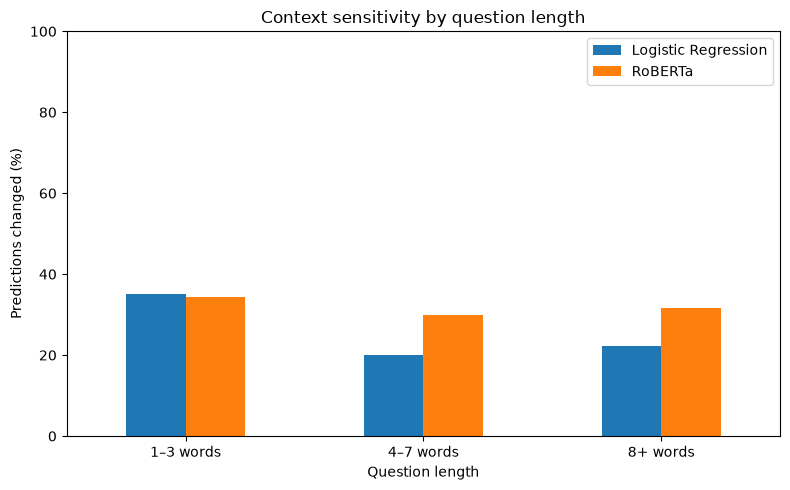

In [20]:
# visualization

length_results[["lr_rate", "roberta_rate"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Context sensitivity by question length")
plt.xlabel("Question length")
plt.ylabel("Predictions changed (%)")
plt.xticks(rotation=0)
plt.legend(["Logistic Regression", "RoBERTa"])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

- highest change rate for both models (and in total) with short questions
- lowest for both with short questions (but 10% lower for logistic regression)
- long questions slightly higher than short for both models, respectively

Question endings (SRAQ):  
- why
- why not
- how
- what
- so


In [22]:
# context sensitivity by question ending

test = pd.read_json("../data/test_processed.jsonl", lines=True)

# Verify that examples are aligned
assert (df["question_lr"].to_numpy() == test["question"].to_numpy()).all()

df["question_ending"] = test["question_ending"].to_numpy()

ending_results = df.groupby("question_ending").agg(
    n=("id", "count"),
    lr_changes=("lr_changed", "sum"),
    lr_rate=("lr_changed", "mean"),
    roberta_changes=("roberta_changed", "sum"),
    roberta_rate=("roberta_changed", "mean")
)

ending_results[["lr_rate", "roberta_rate"]] *= 100

display(ending_results.round(1).sort_values("n", ascending=False))


,n,lr_changes,lr_rate,roberta_changes,roberta_rate
question_ending,,,,,
why not,94,27,28.7,26,27.7
what,89,28,31.5,25,28.1
so,88,32,36.4,34,38.6
how,86,25,29.1,29,33.7
why,81,26,32.1,33,40.7


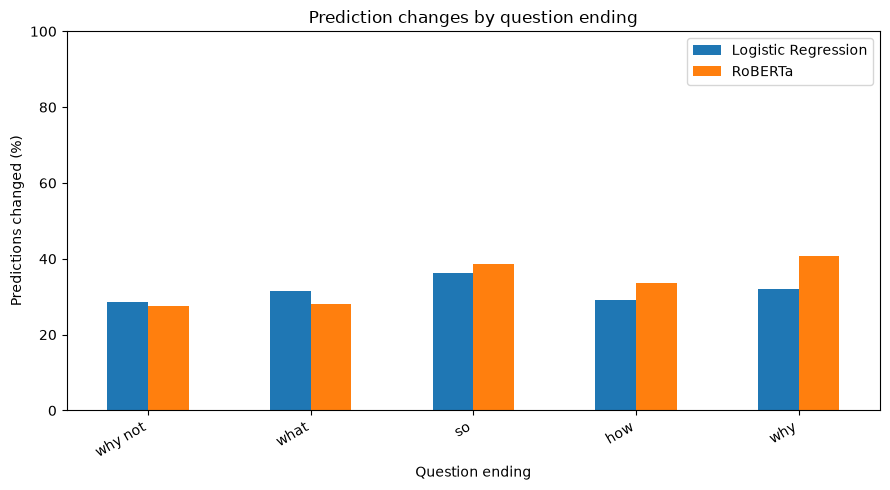

In [23]:
# visualize

plot_data = ending_results.sort_values("n", ascending=False)

ax = plot_data[["lr_rate", "roberta_rate"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Prediction changes by question ending")
plt.xlabel("Question ending")
plt.ylabel("Predictions changed (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(["Logistic Regression", "RoBERTa"])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


- relatively high change rates for "so"
- "why" also high for RoBERTa
- "why not" lowest for both models

In [25]:
# looking at question length distribution by question ending

length_by_ending = pd.crosstab(
    df["question_ending"],
    df["length_group"]
)

display(length_by_ending)


# calculating percentage of each ending category in each length group
length_by_ending_pct = pd.crosstab(
    df["question_ending"],
    df["length_group"],
    normalize="index"
) * 100

display(length_by_ending_pct.round(1))


length_group,1–3 words,4–7 words,8+ words
question_ending,,,
how,63,14,9
so,61,5,22
what,64,10,15
why,69,4,8
why not,68,17,9


length_group,1–3 words,4–7 words,8+ words
question_ending,,,
how,73.3,16.3,10.5
so,69.3,5.7,25.0
what,71.9,11.2,16.9
why,85.2,4.9,9.9
why not,72.3,18.1,9.6


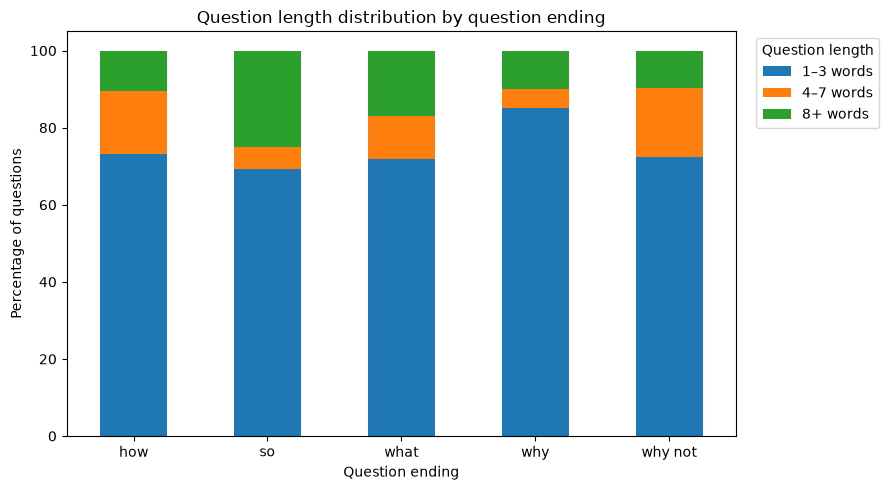

In [26]:
# visualizing

ax = length_by_ending_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Question length distribution by question ending")
plt.xlabel("Question ending")
plt.ylabel("Percentage of questions")
plt.xticks(rotation=0)
plt.legend(title="Question length", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


- all categories have at least 69.3% of very short questions
- "so" has most longer questions
- "why" has most very short questions
- "why not" has most shorter questions  
PERCENTUALLY!

- Logistic Regression: very short questions change more often than longer questions (>10% difference)
- RoBERTa: less difference (between 30 - 35%)
- Question endings:
    - RoBERTa: highest for "why" (40.7% + biggest proportion of very short questions 82.5%) and "so" (38.6% + lowest proportion of very short questions 69.3%)
    - Logistic Regression: highest for "so" (36.4%)

In [ ]:
# prediction-change rates for very short questions

short_questions = df[df["length_group"] == "1–3 words"]

short_results = short_questions.groupby("question_ending").agg(
    n=("id", "count"),
    lr_rate=("lr_changed", "mean"),
    roberta_rate=("roberta_changed", "mean")
)

short_results[["lr_rate", "roberta_rate"]] *= 100

display(short_results.round(1))

,n,lr_rate,roberta_rate
question_ending,,,
how,63,33.3,36.5
so,61,41.0,36.1
what,64,39.1,31.2
why,69,31.9,42.0
why not,68,30.9,26.5


- Logistic Regression:
    - "so": 41.0%
    - "what": 39.1%
    - lowest: 30.9% ("why not")
- RoBERTa:
    - "why": 42.0%
    - "how": 36.5%
    - "so": 36.1%
    - lowest: 26.5% ("why not")  

- very short questions have highest change rate, but also variation within very short questions (looking at question endings)
- different sensitivities between models(except for lowest change rate)